

## Part 1 — Linear Regression: Medical Aid Cost Prediction

### Plan for this stage
1. Load the data and check its basic shape/types.
2. Check for missing values and duplicate rows.
3. Decide, based on what we find, whether/how cleaning is needed before EDA proper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("insurance.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Data types and summary statistics


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


### Missing values and duplicate rows


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of fully duplicated rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of fully duplicated rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


**Decision:** drop the duplicate row. 

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicate:", df.shape)

Shape after dropping duplicate: (1337, 7)


## Exploratory Data Analysis

### 1. Distribution of the target variable (`charges`)

We look at the raw distribution first if it's heavily skewed, that's a signal that a transform such as `log(charges)` might help later.

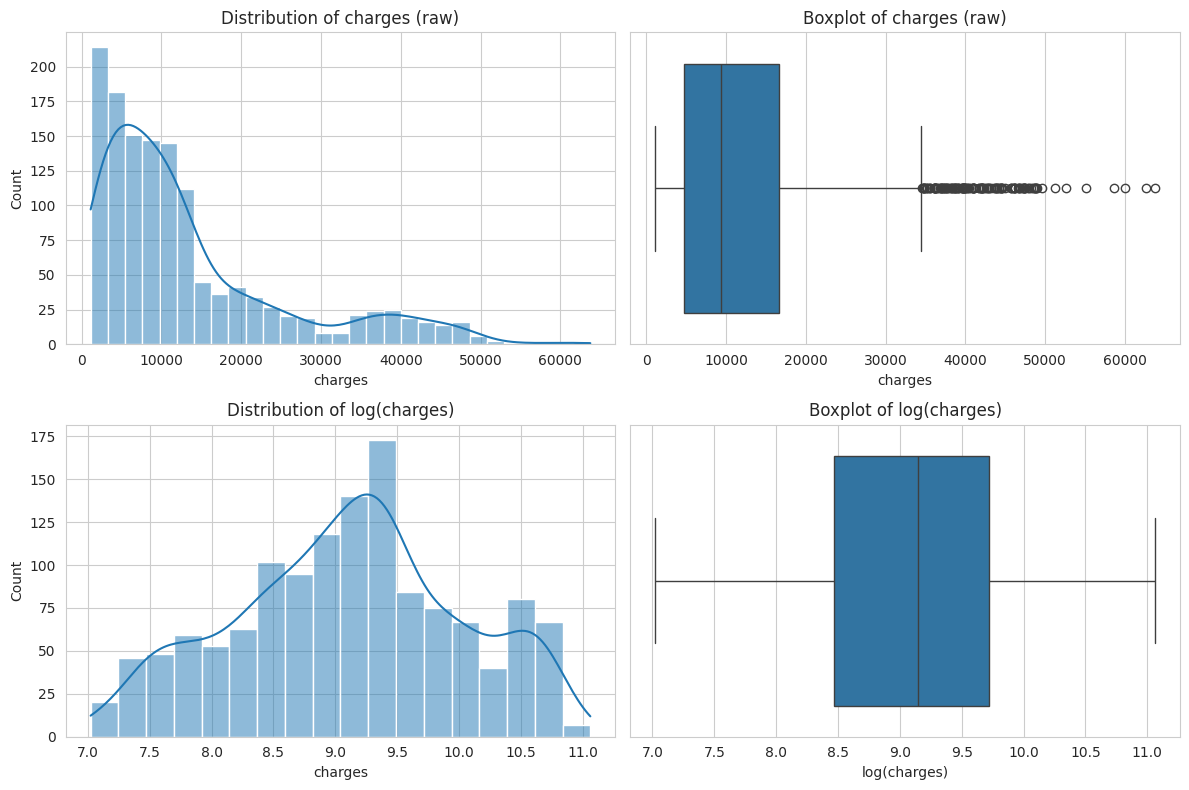

Skewness of charges: 1.5136902413349014
Skewness of log(charges): -0.08973781209745355


In [6]:
from scipy.stats import skew

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["charges"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of charges (raw)")
sns.boxplot(x=df["charges"], ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of charges (raw)")

log_charges = np.log(df["charges"])
sns.histplot(log_charges, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of log(charges)")
sns.boxplot(x=log_charges, ax=axes[1, 1])
axes[1, 1].set_title("Boxplot of log(charges)")
axes[1, 1].set_xlabel("log(charges)")

plt.tight_layout()
plt.show()

print("Skewness of charges:", skew(df["charges"]))
print("Skewness of log(charges):", skew(log_charges))

### 2. Smoker status vs charges



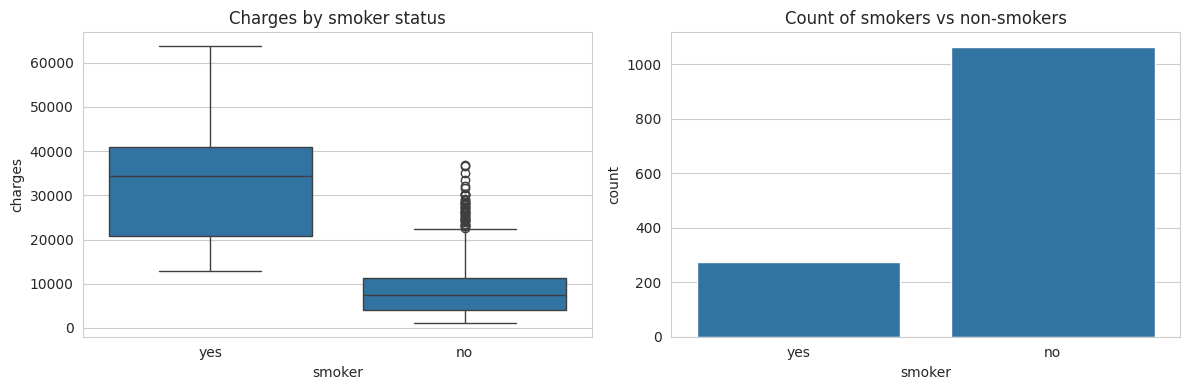

,mean,median,count
smoker,,,
no,8440.660307,7345.72660,1063
yes,32050.231832,34456.34845,274


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="smoker", y="charges", ax=axes[0])
axes[0].set_title("Charges by smoker status")
sns.countplot(data=df, x="smoker", ax=axes[1])
axes[1].set_title("Count of smokers vs non-smokers")
plt.tight_layout()
plt.show()

df.groupby("smoker")["charges"].agg(["mean", "median", "count"])

### 3. Age and BMI vs charges (and interaction with smoking)



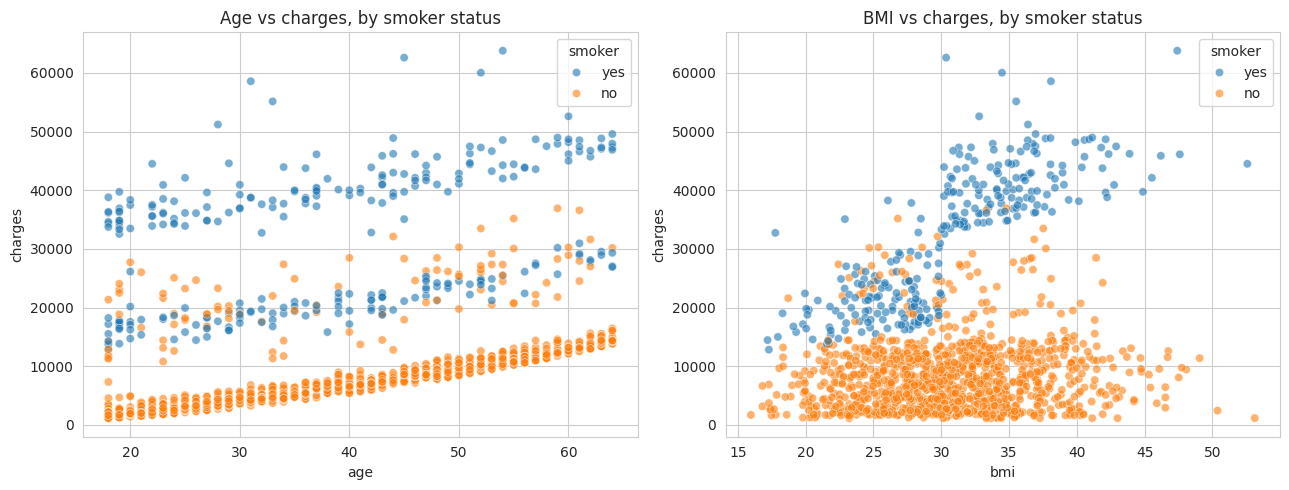

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("Age vs charges, by smoker status")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].set_title("BMI vs charges, by smoker status")
plt.tight_layout()
plt.show()

### 4. Categorical breakdowns: sex, region, children



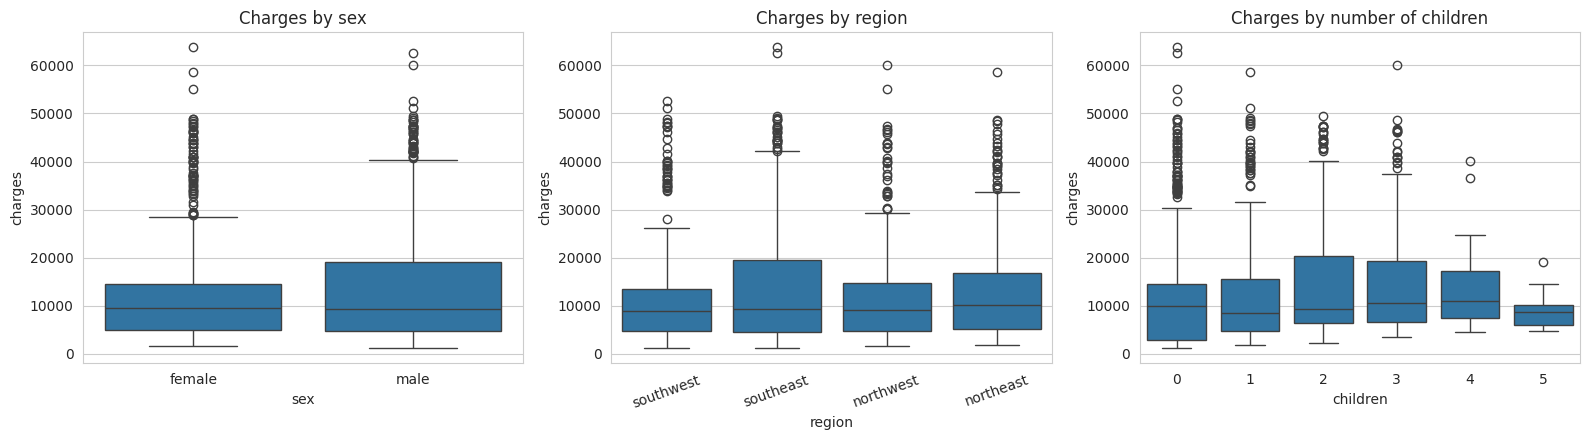

sex
female    12569.578844
male      13974.998864
Name: charges, dtype: float64

region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="sex", y="charges", ax=axes[0])
axes[0].set_title("Charges by sex")
sns.boxplot(data=df, x="region", y="charges", ax=axes[1])
axes[1].set_title("Charges by region")
axes[1].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="children", y="charges", ax=axes[2])
axes[2].set_title("Charges by number of children")
plt.tight_layout()
plt.show()

print(df.groupby("sex")["charges"].mean())
print()
print(df.groupby("region")["charges"].mean())

### 5. Correlation matrix 

For the numeric predictors (`age`, `bmi`, `children`) plus a numeric-encoded `smoker`, we check pairwise correlation. 

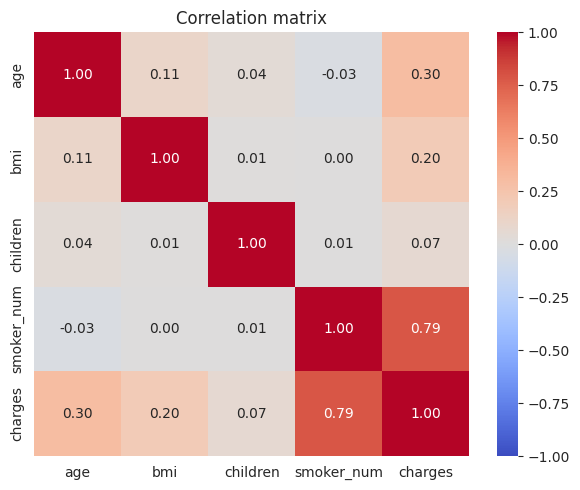

In [10]:
corr_df = df.copy()
corr_df["smoker_num"] = (corr_df["smoker"] == "yes").astype(int)

corr = corr_df[["age", "bmi", "children", "smoker_num", "charges"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()



## Data cleaning and feature engineering


In [11]:
model_df = df.copy()

# Binary-encode sex and smoker
model_df["sex"] = model_df["sex"].map({"female": 0, "male": 1})
model_df["smoker"] = model_df["smoker"].map({"no": 0, "yes": 1})

# One-hot encode region (drop first level -> northeast becomes the reference category)
model_df = pd.get_dummies(model_df, columns=["region"], drop_first=True)
region_cols = [c for c in model_df.columns if c.startswith("region_")]
model_df[region_cols] = model_df[region_cols].astype(int)

# Target: log-transformed charges
model_df["log_charges"] = np.log(model_df["charges"])

# Interaction feature
model_df["bmi_smoker"] = model_df["bmi"] * model_df["smoker"]

model_df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,log_charges,bmi_smoker
0,19,0,27.900,0,1,16884.92400,0,0,1,9.734176,27.9
1,18,1,33.770,1,0,1725.55230,0,1,0,7.453302,0.0
2,28,1,33.000,3,0,4449.46200,0,1,0,8.400538,0.0
3,33,1,22.705,0,0,21984.47061,1,0,0,9.998092,0.0
4,32,1,28.880,0,0,3866.85520,1,0,0,8.260197,0.0


## Train/test split 

In [12]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(model_df, test_size=0.2, random_state=42)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (1069, 11)
Test shape: (268, 11)


## Feature selection: backward elimination on P-values



In [13]:
import statsmodels.api as sm

candidate_features = ["age", "sex", "bmi", "children", "smoker", "bmi_smoker"] + region_cols
force_keep = ["bmi", "smoker", "bmi_smoker"]

X_train = train_df[candidate_features].astype(float)
y_train = train_df["log_charges"]

def backward_elimination(X, y, sig_level=0.05, force_keep=None, verbose=True):
    force_keep = force_keep or []
    features = list(X.columns)
    while True:
        X_with_const = sm.add_constant(X[features])
        model = sm.OLS(y, X_with_const).fit()
        pvalues = model.pvalues.drop("const")
        droppable = pvalues.drop(labels=[f for f in force_keep if f in pvalues.index])
        if droppable.empty:
            break
        worst_feature, worst_p = droppable.idxmax(), droppable.max()
        if worst_p > sig_level:
            if verbose:
                print(f"Dropping '{worst_feature}' (p = {worst_p:.4f})")
            features.remove(worst_feature)
        else:
            break
    return features, model

selected_features, ols_model = backward_elimination(X_train, y_train, force_keep=force_keep)
print("\nFinal selected features:", selected_features)
ols_model.summary()

Dropping 'region_northwest' (p = 0.2430)

Final selected features: ['age', 'sex', 'bmi', 'children', 'smoker', 'bmi_smoker', 'region_southeast', 'region_southwest']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            log_charges   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.765
Method:                 Least Squares   F-statistic:                     436.3
Date:                Sun, 13 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:33:49   Log-Likelihood:                -633.20
No. Observations:                1069   AIC:                             1284.
Df Residuals:                    1060   BIC:                             1329.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                7.3403      0.085     86.051      0.000       7.173       7.508
age                  0.0344      0.001     35.337      0.000       0.032       0.036
sex                 -0.0952      0.027     -3.512      0.000      -0.148      -0.042
bmi                  0.0028      0.003      1.089      0.277      -0.002       0.008
children             0.1002      0.011      8.880      0.000       0.078       0.122
smoker               0.0413      0.170      0.243      0.808      -0.293       0.376
bmi_smoker           0.0494      0.006      8.971      0.000       0.039       0.060
region_southeast    -0.1072      0.034     -3.166      0.002      -0.174      -0.041
region_southwest    -0.0856      0.033     -2.566      0.010      -0.151      -0.020
==============================================================================
Omnibus:                      415.145   Durbin-Watson:                   1.885
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1676.557
Skew:                           1.837   Prob(JB):                         0.00
Kurtosis:                       7.914   Cond. No.                         671.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Train the final model


In [14]:
from sklearn.linear_model import LinearRegression

X_train_final = train_df[selected_features]
y_train_final = train_df["log_charges"]
X_test_final = test_df[selected_features]
y_test_final = test_df["log_charges"]

lr = LinearRegression()
lr.fit(X_train_final, y_train_final)

coef_table = pd.Series(lr.coef_, index=selected_features)
coef_table["intercept"] = lr.intercept_
coef_table.sort_values(key=abs, ascending=False)

intercept           7.340274
region_southeast   -0.107247
children            0.100176
sex                -0.095227
region_southwest   -0.085619
bmi_smoker          0.049404
smoker              0.041340
age                 0.034370
bmi                 0.002836
dtype: float64

## Evaluate the model



In [15]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_train_pred_log = lr.predict(X_train_final)
y_test_pred_log = lr.predict(X_test_final)

y_test_actual = test_df["charges"].values
y_test_pred_actual = np.exp(y_test_pred_log)

r2_train_log = r2_score(y_train_final, y_train_pred_log)
r2_test_log = r2_score(y_test_final, y_test_pred_log)
rmse_dollar = np.sqrt(mean_squared_error(y_test_actual, y_test_pred_actual))
mae_dollar = mean_absolute_error(y_test_actual, y_test_pred_actual)

print(f"R² (log scale)  — train: {r2_train_log:.4f}   test: {r2_test_log:.4f}")
print(f"RMSE (Rand, back-transformed, test set): {rmse_dollar:,.2f}")
print(f"MAE  (Rand, back-transformed, test set): {mae_dollar:,.2f}")
print(f"For reference, mean charges in the test set: {y_test_actual.mean():,.2f}")

R² (log scale)  — train: 0.7670   test: 0.8353
RMSE (Rand, back-transformed, test set): 8,734.21
MAE  (Rand, back-transformed, test set): 4,216.76
For reference, mean charges in the test set: 14,272.01


### Residual diagnostics



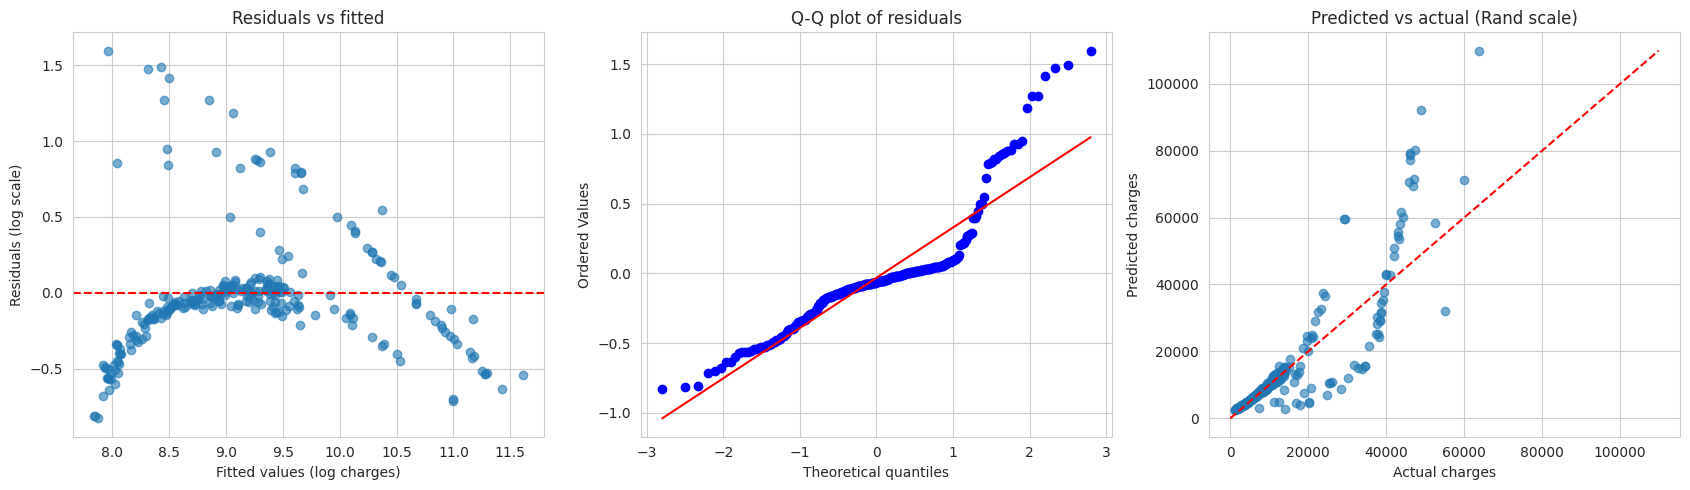

In [16]:
import scipy.stats as stats

residuals_log = y_test_final.values - y_test_pred_log

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test_pred_log, residuals_log, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted values (log charges)")
axes[0].set_ylabel("Residuals (log scale)")
axes[0].set_title("Residuals vs fitted")

stats.probplot(residuals_log, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of residuals")

axes[2].scatter(y_test_actual, y_test_pred_actual, alpha=0.6)
lims = [0, max(y_test_actual.max(), y_test_pred_actual.max())]
axes[2].plot(lims, lims, color="red", linestyle="--")
axes[2].set_xlabel("Actual charges")
axes[2].set_ylabel("Predicted charges")
axes[2].set_title("Predicted vs actual (Rand scale)")

plt.tight_layout()
plt.show()

## Retraining: addressing the underprediction pattern



In [17]:
train_df = train_df.copy()
test_df = test_df.copy()

for d in (train_df, test_df):
    d["obese"] = (d["bmi"] >= 30).astype(int)
    d["obese_smoker"] = d["obese"] * d["smoker"]

candidate_features_v2 = ["age", "sex", "bmi", "children", "smoker", "obese", "obese_smoker"] + region_cols
force_keep_v2 = ["smoker", "obese", "obese_smoker"]

X_train_v2 = train_df[candidate_features_v2].astype(float)
y_train_v2 = train_df["log_charges"]

selected_features_v2, ols_model_v2 = backward_elimination(X_train_v2, y_train_v2, force_keep=force_keep_v2)
print("\nFinal selected features (v2):", selected_features_v2)
ols_model_v2.summary()

Dropping 'region_northwest' (p = 0.3589)
Dropping 'bmi' (p = 0.2205)

Final selected features (v2): ['age', 'sex', 'children', 'smoker', 'obese', 'obese_smoker', 'region_southeast', 'region_southwest']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            log_charges   R-squared:                       0.771
Model:                            OLS   Adj. R-squared:                  0.770
Method:                 Least Squares   F-statistic:                     447.2
Date:                Sun, 13 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:33:50   Log-Likelihood:                -623.08
No. Observations:                1069   AIC:                             1264.
Df Residuals:                    1060   BIC:                             1309.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                7.4018      0.047    156.555      0.000       7.309       7.495
age                  0.0345      0.001     35.905      0.000       0.033       0.036
sex                 -0.0884      0.027     -3.299      0.001      -0.141      -0.036
children             0.0999      0.011      8.942      0.000       0.078       0.122
smoker               1.2057      0.047     25.424      0.000       1.113       1.299
obese                0.0329      0.030      1.083      0.279      -0.027       0.092
obese_smoker         0.6598      0.067      9.879      0.000       0.529       0.791
region_southeast    -0.0920      0.033     -2.812      0.005      -0.156      -0.028
region_southwest    -0.0971      0.033     -2.934      0.003      -0.162      -0.032
==============================================================================
Omnibus:                      423.140   Durbin-Watson:                   1.865
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1773.366
Skew:                           1.861   Prob(JB):                         0.00
Kurtosis:                       8.095   Cond. No.                         246.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
X_train_final_v2 = train_df[selected_features_v2]
y_train_final_v2 = train_df["log_charges"]
X_test_final_v2 = test_df[selected_features_v2]
y_test_final_v2 = test_df["log_charges"]

lr_v2 = LinearRegression()
lr_v2.fit(X_train_final_v2, y_train_final_v2)

y_train_pred_log_v2 = lr_v2.predict(X_train_final_v2)
y_test_pred_log_v2 = lr_v2.predict(X_test_final_v2)
y_test_pred_actual_v2 = np.exp(y_test_pred_log_v2)

r2_train_log_v2 = r2_score(y_train_final_v2, y_train_pred_log_v2)
r2_test_log_v2 = r2_score(y_test_final_v2, y_test_pred_log_v2)
rmse_dollar_v2 = np.sqrt(mean_squared_error(y_test_actual, y_test_pred_actual_v2))
mae_dollar_v2 = mean_absolute_error(y_test_actual, y_test_pred_actual_v2)

comparison = pd.DataFrame({
    "v1 (continuous bmi×smoker)": [r2_train_log, r2_test_log, rmse_dollar, mae_dollar],
    "v2 (obese threshold ×smoker)": [r2_train_log_v2, r2_test_log_v2, rmse_dollar_v2, mae_dollar_v2],
}, index=["R² train (log)", "R² test (log)", "RMSE test (Rand)", "MAE test (Rand)"])
comparison

,v1 (continuous bmi×smoker),v2 (obese threshold ×smoker)
R² train (log),0.767048,0.771418
R² test (log),0.835260,0.840868
RMSE test (Rand),8734.206803,7807.516867
MAE test (Rand),4216.755585,3868.473394


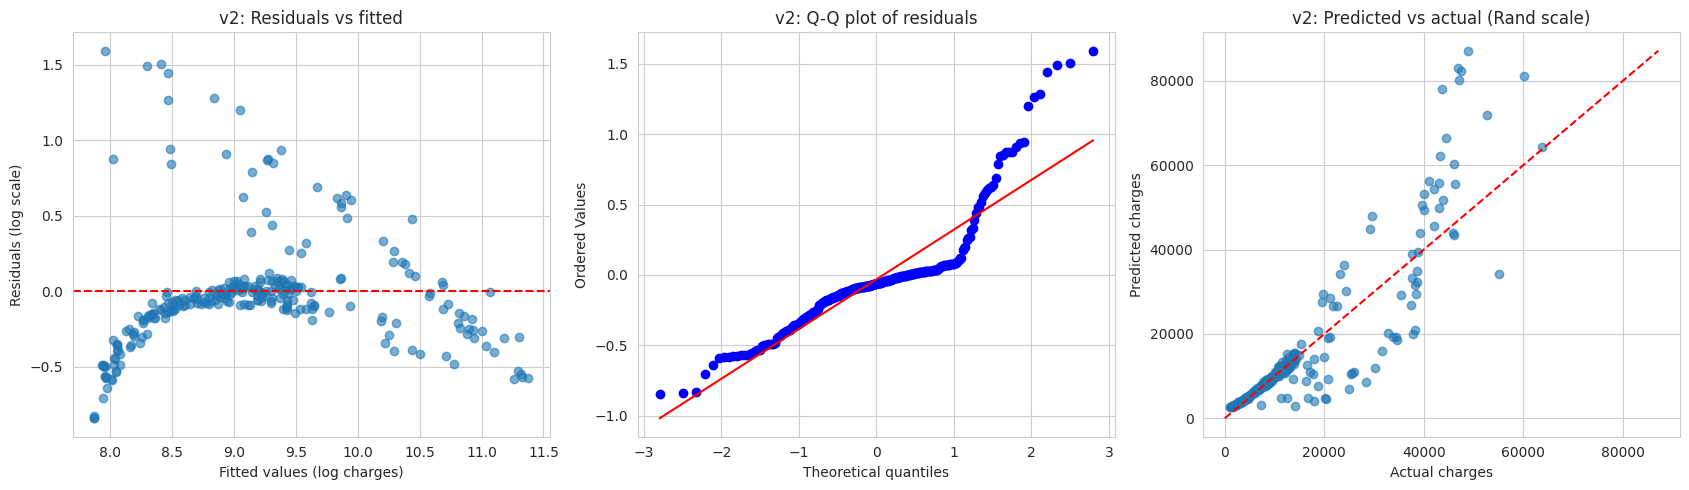

In [19]:
residuals_log_v2 = y_test_final_v2.values - y_test_pred_log_v2

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test_pred_log_v2, residuals_log_v2, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted values (log charges)")
axes[0].set_ylabel("Residuals (log scale)")
axes[0].set_title("v2: Residuals vs fitted")

stats.probplot(residuals_log_v2, dist="norm", plot=axes[1])
axes[1].set_title("v2: Q-Q plot of residuals")

axes[2].scatter(y_test_actual, np.exp(y_test_pred_log_v2), alpha=0.6)
lims = [0, max(y_test_actual.max(), np.exp(y_test_pred_log_v2).max())]
axes[2].plot(lims, lims, color="red", linestyle="--")
axes[2].set_xlabel("Actual charges")
axes[2].set_ylabel("Predicted charges")
axes[2].set_title("v2: Predicted vs actual (Rand scale)")

plt.tight_layout()
plt.show()